**CURSO**: Análisis Geoespacial, Departamento de Geociencias y Medio Ambiente, Universidad Nacional de Colombia - sede Medellín <br/>
**Profesor**: Edier Aristizábal (evaristizabalg@unal.edu.co) <br />
**Créditos**: El contenido de este notebook proviene de [ASLAN](https://medium.com/nerd-for-tech/atmospheric-correction-of-satellite-images-using-python-42128504afc3), [Steve Attila](https://towardsdatascience.com/displaying-a-gridded-dataset-on-a-web-based-map-ad6bbe90247f)  Se ha hecho todo lo posible por identificar a los titulares de los derechos de los materiales usados en este notebook. El autor se disculpa por cualquier omisión involuntaria y con gusto agregará el reconocimiento en futuras ediciones.

In [ ]:
import warnings
warnings.simplefilter("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure
from osgeo import gdal
import os
import geopandas as gpd
import rioxarray as rxr
import fiona
from lxml import etree

import rasterio as rio
from rasterio.plot import show, show_hist
import rasterio.mask
from rasterio.merge import merge
from rasterio.crs import CRS
from rasterio import mask as msk

from shapely.geometry import mapping


# Raster geospatial data

Los datos geoespaciales usan GeoTIFF y otros formatos para organizar y almacenar conjuntos de datos ráster en grilla, como imágenes de satélite y modelos del terreno. GDAL (Geospatial Data Abstraction Library) es la librería estándar de facto para interactuar con datos ráster geoespaciales y manipularlos. Su propósito principal, o el de cualquier librería basada en GDAL, es leer, escribir y transformar conjuntos de datos geoespaciales de forma coherente con sus metadatos espaciales. Las librerías más usadas se apoyan en GDAL, como rasterio, xarray y rioxarray.

[Rasterio](https://rasterio.readthedocs.io/en/latest/) lee y escribe estos formatos y ofrece una API de Python basada en arreglos N-dimensionales de Numpy y en GeoJSON.

[xarray](http://xarray.pydata.org/en/stable/) es un proyecto de código abierto y un paquete de Python para trabajar con arreglos multidimensionales etiquetados.

[Rioxarray](https://github.com/corteva/rioxarray) (con sus dependencias xarray y rasterio) es un módulo bastante completo para manejar conjuntos de datos geográficos en grilla, como un GeoTIFF.

## Digital Elevation Models (DEM's)

El Global Multi-resolution Terrain Elevation Data 2010 (GMTED2010) contiene siete nuevos productos ráster de elevación para cada una de las resoluciones espaciales de 30, 15 y 7,5 segundos de arco, e incorpora los mejores datos globales de elevación disponibles actualmente. Los productos se generaron con los siguientes métodos de agregación: elevación mínima, máxima, media y mediana, desviación estándar de la elevación, submuestreo sistemático y énfasis en líneas de quiebre. Los datos son de uso libre y en este [enlace](https://www.usgs.gov/centers/eros/science/usgs-eros-archive-digital-elevation-global-multi-resolution-terrain-elevation) hay más información sobre su uso.

In [ ]:
file = rasterio.open('G:/My Drive/INVESTIGACION/Cartografia/CC_SRTM_30m.tif')
dataset = file.read()
print(dataset.shape)

(1, 7807, 6592)


In [ ]:
file.crs

CRS.from_epsg(3116)

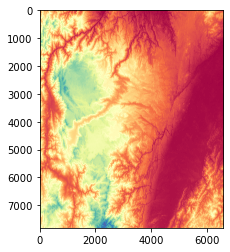

In [ ]:
plt.imshow(dataset[0], cmap='Spectral')
plt.show()

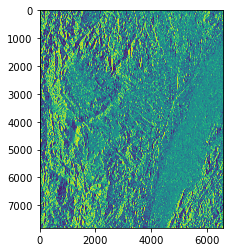

In [ ]:
import earthpy.spatial as es
hillshade = es.hillshade(dataset[0], azimuth=270, altitude=1)
plt.imshow(hillshade)

In [ ]:
df = gpd.read_file('G:/My Drive/INVESTIGACION/Cartografia/Barrios.shp')
df.head(2)

,OBJECTID,ID_BARRIO,S_NOMBARRI,ID_MPIO,ID_CONBARR,ID_COMUNA,geometry
0,1,14,San Jose,266,052660000014,00,"POLYGON ((-75.58064 6.16393, -75.58057 6.16369..."
1,2,11,La Paz,266,052660000011,00,"POLYGON ((-75.58988 6.16203, -75.59002 6.16135..."


In [ ]:
df2=df.to_crs(epsg=3116)

<AxesSubplot:>

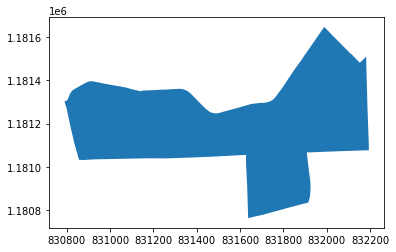

In [ ]:
barrio = df2.loc[df['S_NOMBARRI'] == 'Belén']
barrio.plot()

In [ ]:
clipped_array, clipped_transform = msk.mask(file, [mapping(barrio.iloc[0].geometry)], crop=True)

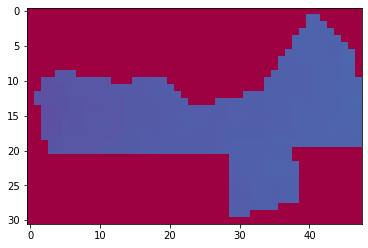

In [ ]:
plt.imshow(clipped_array[0], cmap='Spectral')
plt.show()

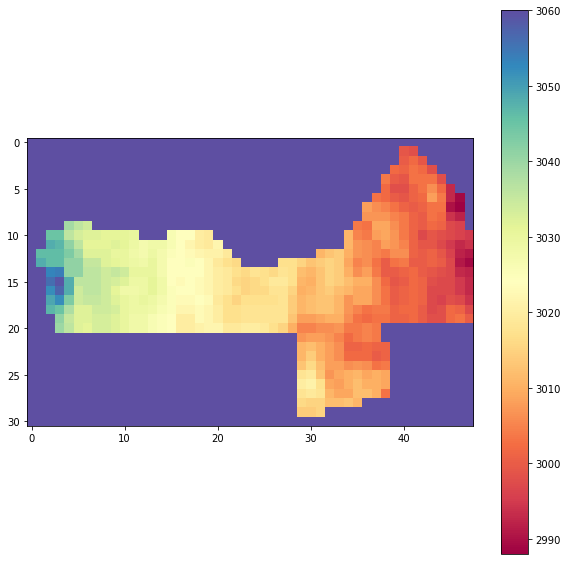

In [ ]:
 def clip_raster(gdf, img):
     clipped_array, clipped_transform = msk.mask(img, [mapping(gdf.iloc[0].geometry)], crop=True)
     clipped_array, clipped_transform = msk.mask(img, [mapping(gdf.iloc[0].geometry)],
                                                           crop=True, nodata=(np.amax(clipped_array[0]) + 1))
     clipped_array[0] = clipped_array[0] + abs(np.amin(clipped_array))
     value_range = np.amax(clipped_array) + abs(np.amin(clipped_array))
     return clipped_array, value_range

barrio_topography, value_range = clip_raster(barrio, file)

plt.figure(figsize=(10,10))
c = plt.imshow(barrio_topography[0], cmap='Spectral')
plt.colorbar(c)
plt.show()

## Algebra de mapas

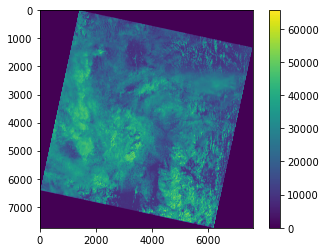

In [ ]:
im = gdal.Open("https://landsat-pds.s3.amazonaws.com/c1/L8/009/056/LO08_L1TP_009056_20201108_20201120_01_T1/LO08_L1TP_009056_20201108_20201120_01_T1_B2.TIF")
im = im.ReadAsArray().astype(np.float)
plt.imshow(im)
plt.colorbar()

In [ ]:
b5_ = gdal.Open("https://landsat-pds.s3.amazonaws.com/c1/L8/009/056/LO08_L1TP_009056_20201108_20201120_01_T1/LO08_L1TP_009056_20201108_20201120_01_T1_B5.TIF")
b5 = b5_.ReadAsArray()
b4_ = gdal.Open("https://landsat-pds.s3.amazonaws.com/c1/L8/009/056/LO08_L1TP_009056_20201108_20201120_01_T1/LO08_L1TP_009056_20201108_20201120_01_T1_B4.TIF")
b4 = b4_.ReadAsArray()
b3_ = gdal.Open("https://landsat-pds.s3.amazonaws.com/c1/L8/009/056/LO08_L1TP_009056_20201108_20201120_01_T1/LO08_L1TP_009056_20201108_20201120_01_T1_B3.TIF")
b3 = b3_.ReadAsArray()
b2_ = gdal.Open("https://landsat-pds.s3.amazonaws.com/c1/L8/009/056/LO08_L1TP_009056_20201108_20201120_01_T1/LO08_L1TP_009056_20201108_20201120_01_T1_B2.TIF")
b2 = b2_.ReadAsArray()

In [ ]:
b5

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], dtype=uint16)

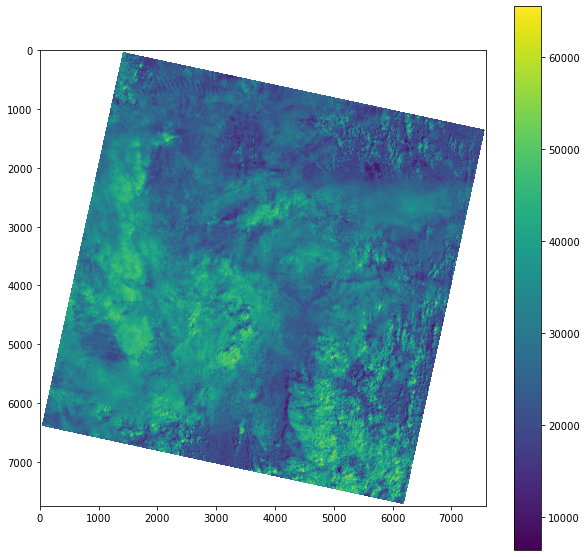

In [ ]:
b5_nan=np.where(b5==0,np.nan,b5)
plt.figure(figsize=(10,10))
plt.imshow(b5_nan)
plt.colorbar()

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


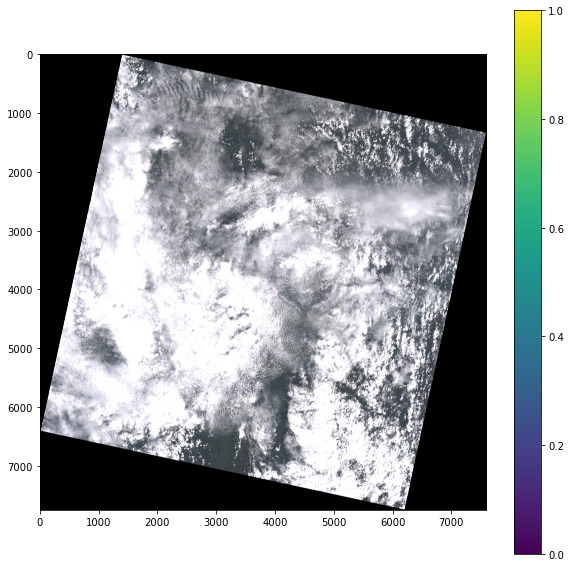

In [ ]:
rgb = np.stack([b4, b3, b2], axis=-1)
rgb = rgb/rgb.max() * 2.0
plt.figure(figsize=(10,10))
plt.imshow(rgb)
plt.colorbar()

In [ ]:
FalseColor = np.stack([b5, b3, b2], axis=-1)
FalseColor = FalseColor/rgb.max() * 2.0
plt.figure(figsize=(10,10))
plt.imshow(FalseColor)
plt.colorbar()

### Index

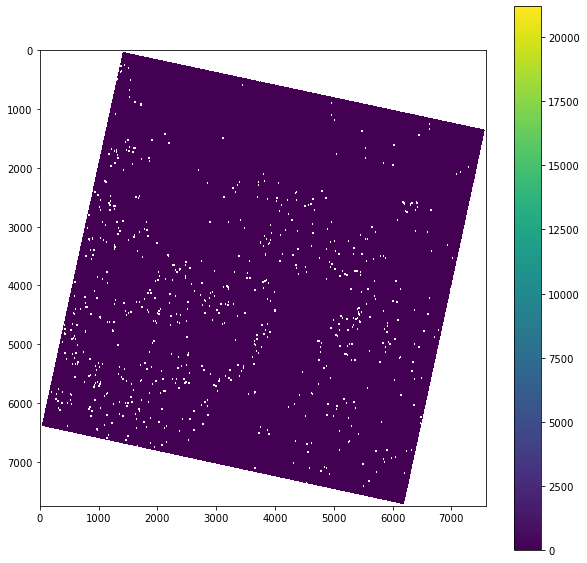

In [ ]:
NDVI = (b5-b4)/(b5+b4)
plt.figure(figsize=(10,10))
plt.imshow(NDVI)
plt.colorbar()

### Rasterio

In [ ]:
satdat = rio.open("https://hello.planet.com/data/s/UG2TX98suVmmi9q/download")

In [ ]:
blue, green, red, nir = satdat.read()

In [ ]:
# O leer todo el conjunto de datos en un solo arreglo 3D:
data = satdat.read()

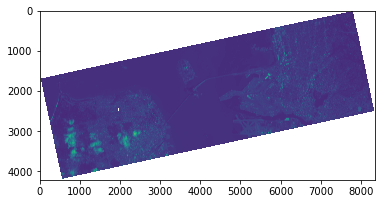

<AxesSubplot:>

In [ ]:
blue = np.where(blue==0,np.nan, blue)
show(blue)

In [ ]:
B1=satdat.read(1)
B2=satdat.read(2)
B3=satdat.read(3)

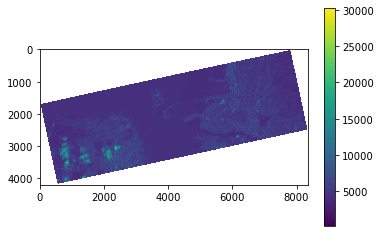

In [ ]:
b1 = np.where(B1==0,np.nan, B1)
plt.imshow(b1)
plt.colorbar()

In [ ]:
vector=B1.ravel()
vector_rec=vector[vector!=0]
vector_rec.mean()

5056.31088110179

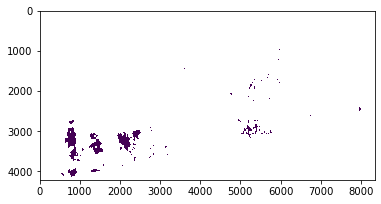

<AxesSubplot:>

In [ ]:
check = np.logical_and ( B1 > 5000, B1 < 30000 )
B1_rango=np.where(check,1,np.nan)
show(B1_rango)

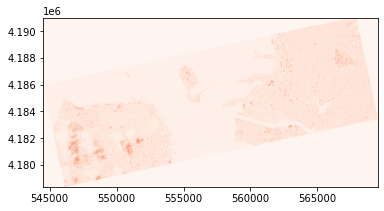

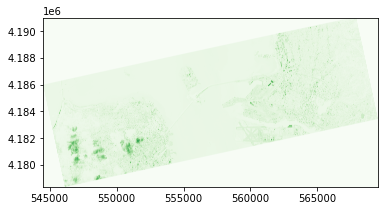

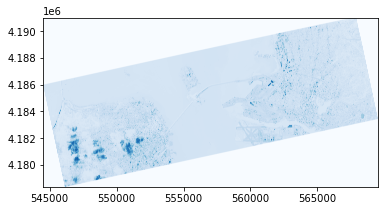

<AxesSubplot:>

In [ ]:
show((satdat, 4), cmap='Reds')
show((satdat, 3), cmap='Greens')
show((satdat, 2), cmap='Blues')

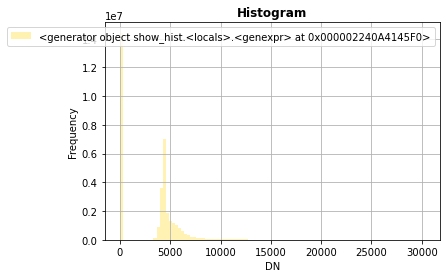

In [ ]:
show_hist(B1, bins=100, lw=0.0, stacked=False, alpha=0.3,histtype='stepfilled', title="Histogram")

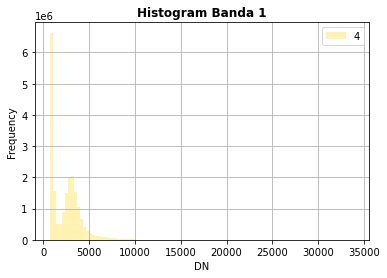

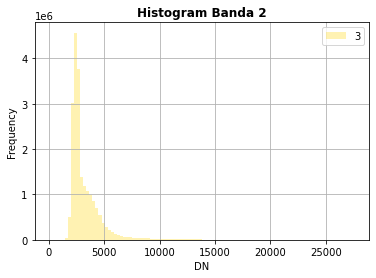

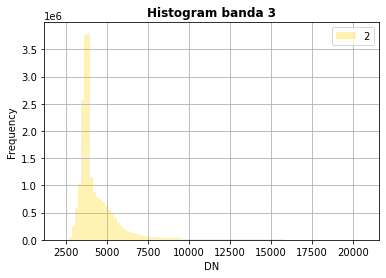

In [ ]:
show_hist((satdat,4), bins=100, lw=0.0, stacked=False, alpha=0.3,histtype='stepfilled', title="Histogram Banda 1")
show_hist((satdat,3), bins=100, lw=0.0, stacked=False, alpha=0.3,histtype='stepfilled', title="Histogram Banda 2")
show_hist((satdat,2), bins=100, lw=0.0, stacked=False, alpha=0.3,histtype='stepfilled', title="Histogram banda 3")

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


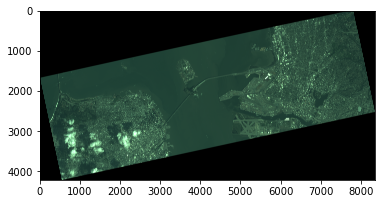

<AxesSubplot:>

In [ ]:
from rasterio.plot import show, adjust_band
imgdata = np.array([adjust_band(satdat.read(i)) for i in (3,2,1)])
show(imgdata*1.5)  # factor para aumentar el brillo

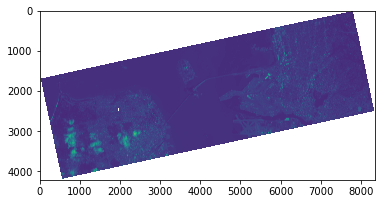

<AxesSubplot:>

In [ ]:
vector=B1.ravel()
vector_rec=vector[vector!=0]
vector_rec.mean()

B1_nan=np.where(B1==0,np.nan,B1)
show(B1_nan)

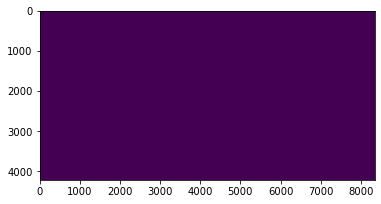

In [ ]:
check = np.logical_and ( B1_nan > 100, B1_nan < 120 )
B1_rango=np.where(check,1,0)
show(B1_rango);

# Satellite Imagery Analysis using Python

## Import Modules

In [ ]:
!pip install earthpy

In [ ]:
from glob import glob

import earthpy as et
import earthpy.spatial as es
import earthpy.plot as ep

import rasterio as rio
from rasterio.plot import plotting_extent
from rasterio.plot import show
from rasterio.plot import reshape_as_raster, reshape_as_image

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap

import plotly.graph_objects as go

np.seterr(divide='ignore', invalid='ignore')

{'divide': 'warn', 'over': 'warn', 'under': 'ignore', 'invalid': 'warn'}

## Sentine 2 Band Details

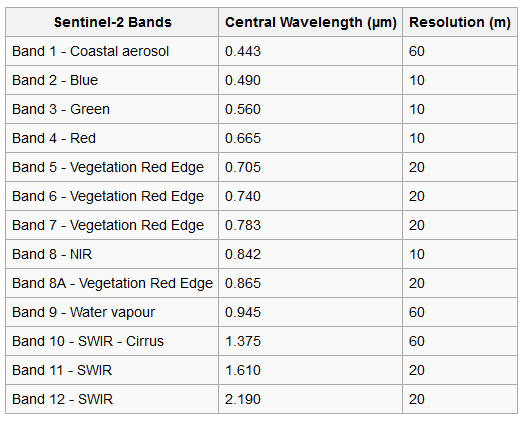

# DataSet

## Sundarbans Satellite Data

In [ ]:
S_sentinel_bands = glob(r"G:\My Drive\CATEDRA\ANALISIS GEOESPACIAL\DATA\sundarbans_data/*B?*.tiff")
S_sentinel_bands.sort()
S_sentinel_bands

['G:\\My Drive\\CATEDRA\\ANALISIS GEOESPACIAL\\DATA\\sundarbans_data\\2020-01-27-00_00_2020-01-27-23_59_Sentinel-2_L2A_B01_(Raw).tiff',
 'G:\\My Drive\\CATEDRA\\ANALISIS GEOESPACIAL\\DATA\\sundarbans_data\\2020-01-27-00_00_2020-01-27-23_59_Sentinel-2_L2A_B02_(Raw).tiff',
 'G:\\My Drive\\CATEDRA\\ANALISIS GEOESPACIAL\\DATA\\sundarbans_data\\2020-01-27-00_00_2020-01-27-23_59_Sentinel-2_L2A_B03_(Raw).tiff',
 'G:\\My Drive\\CATEDRA\\ANALISIS GEOESPACIAL\\DATA\\sundarbans_data\\2020-01-27-00_00_2020-01-27-23_59_Sentinel-2_L2A_B04_(Raw).tiff',
 'G:\\My Drive\\CATEDRA\\ANALISIS GEOESPACIAL\\DATA\\sundarbans_data\\2020-01-27-00_00_2020-01-27-23_59_Sentinel-2_L2A_B05_(Raw).tiff',
 'G:\\My Drive\\CATEDRA\\ANALISIS GEOESPACIAL\\DATA\\sundarbans_data\\2020-01-27-00_00_2020-01-27-23_59_Sentinel-2_L2A_B06_(Raw).tiff',
 'G:\\My Drive\\CATEDRA\\ANALISIS GEOESPACIAL\\DATA\\sundarbans_data\\2020-01-27-00_00_2020-01-27-23_59_Sentinel-2_L2A_B07_(Raw).tiff',
 'G:\\My Drive\\CATEDRA\\ANALISIS GEOESPACIAL\\D

In [ ]:
l = []
for i in S_sentinel_bands:
  with rio.open(i, 'r') as f:
    l.append(f.read(1))


In [ ]:
arr_st = np.stack(l)

In [ ]:
print(f'Height: {arr_st.shape[1]}\nWidth: {arr_st.shape[2]}\nBands: {arr_st.shape[0]}')

In [ ]:
arr_st.shape

(12, 954, 298)

## Visualize Data
### Bands

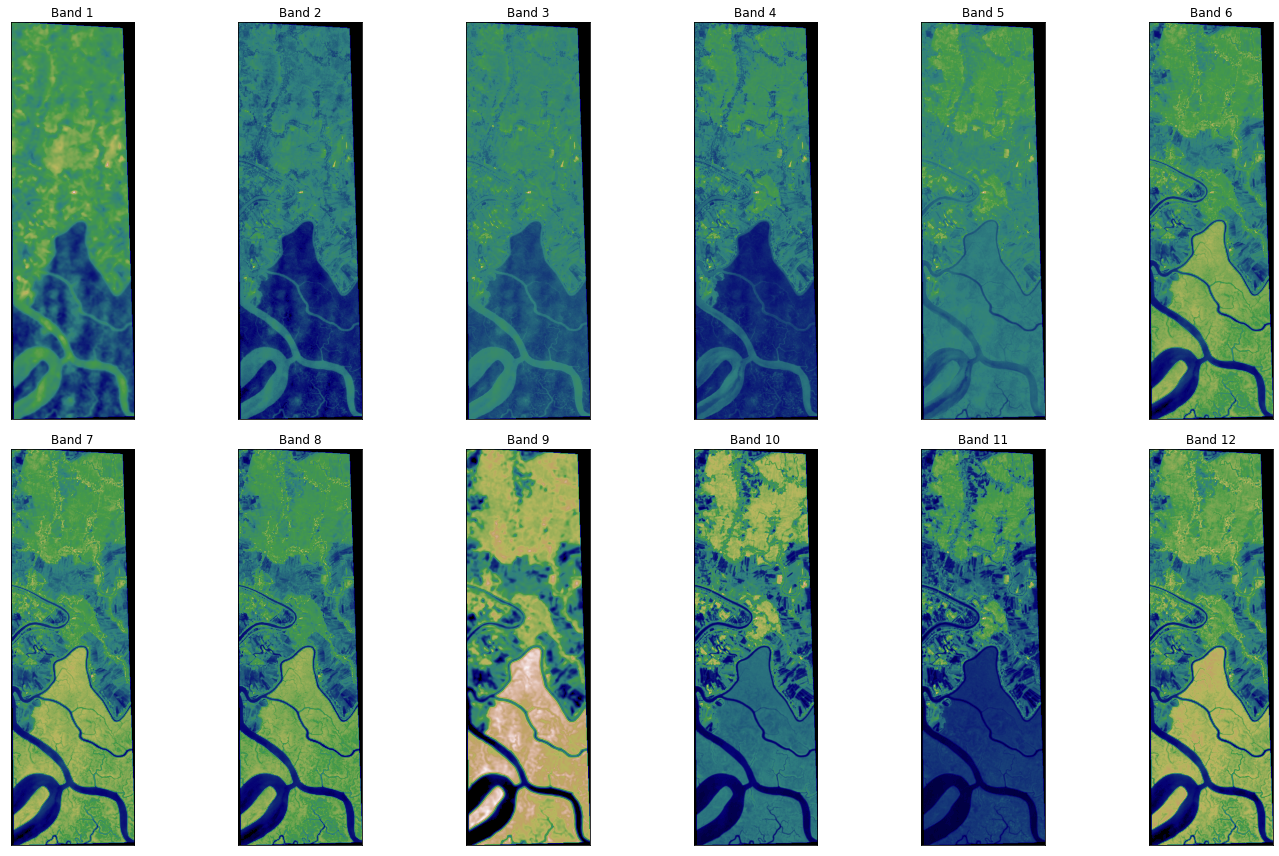

In [ ]:
ep.plot_bands(arr_st, cmap = 'gist_earth', figsize = (20, 12), cols = 6, cbar = False)
plt.show()

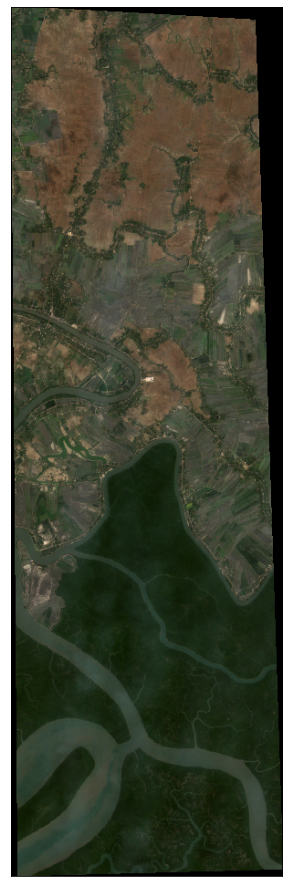

In [ ]:
rgb = ep.plot_rgb(arr_st,  rgb=(3,2,1),
                  figsize=(10, 16),
                # title='RGB Composite Image'
                  )

plt.show()

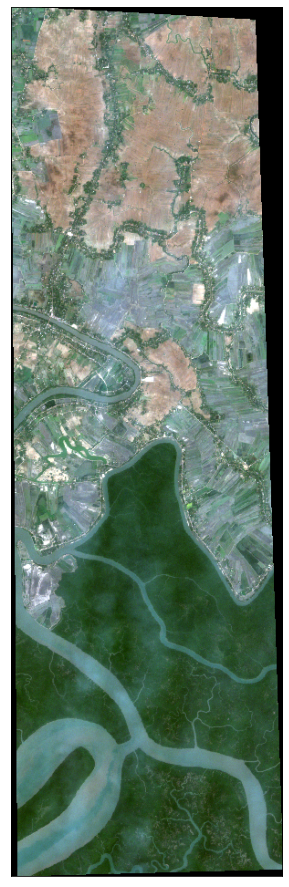

In [ ]:
ep.plot_rgb(
    arr_st,
    rgb=(3, 2, 1),
    stretch=True,
    str_clip=0.2,
    figsize=(10, 16),
    # title="RGB Composite Image with Stretch Applied",
)

plt.show()

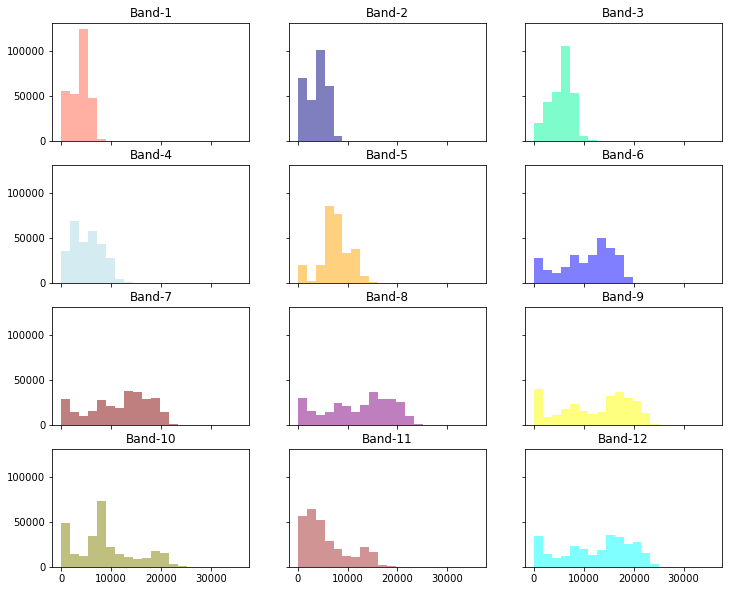

In [ ]:
colors = ['tomato', 'navy', 'MediumSpringGreen', 'lightblue', 'orange', 'blue',
          'maroon', 'purple', 'yellow', 'olive', 'brown', 'cyan']

ep.hist(arr_st,
         colors = colors,
        title=[f'Band-{i}' for i in range(1, 13)],
        cols=3,
        alpha=0.5,
        figsize = (12, 10)
        )

plt.show()

# Vegetation and soils indices

## Índice de Vegetación de Diferencia Normalizada (NDVI)
```
NDVI = ((NIR - Red)/(NIR + Red))
```

* NIR = valores de los píxeles en la banda del infrarrojo cercano
* Red = valores de los píxeles en la banda roja

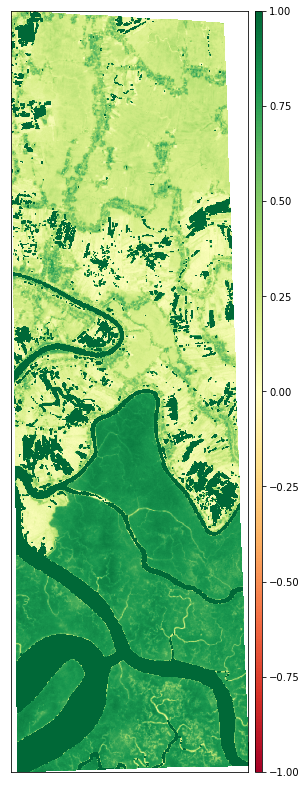

In [ ]:
ndvi = es.normalized_diff(arr_st[7], arr_st[3])

ep.plot_bands(ndvi, cmap="RdYlGn", cols=1, vmin=-1, vmax=1, figsize=(10, 14))

plt.show()

## Índice de Vegetación Ajustado al Suelo (SAVI)

```
SAVI = ((NIR - Red) / (NIR + Red + L)) x (1 + L)
```
* NIR = valores de los píxeles en la banda del infrarrojo cercano
* Red = valores de los píxeles en la banda roja
* L = factor de cobertura de vegetación verde

In [ ]:
L = 0.5

savi = ((arr_st[7] - arr_st[3]) / (arr_st[7] + arr_st[3] + L)) * (1 + L)

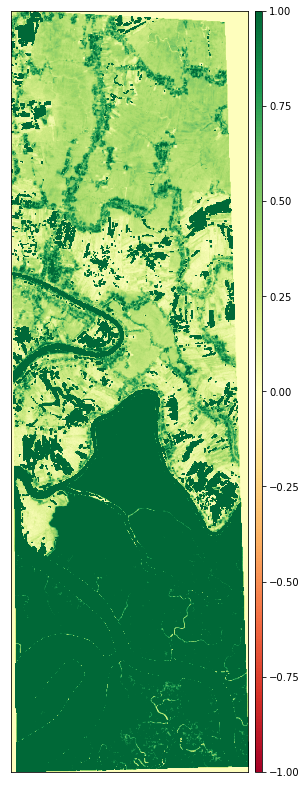

In [ ]:
ep.plot_bands(savi, cmap="RdYlGn", cols=1, vmin=-1, vmax=1, figsize=(10, 14))

plt.show()

## Índice Visible Resistente a la Atmósfera (VARI)
```
VARI = (Green - Red)/ (Green + Red - Blue)
```
* Green = valores de los píxeles en la banda verde
* Red = valores de los píxeles en la banda roja
* Blue = valores de los píxeles en la banda azul

In [ ]:
vari = (arr_st[2] - arr_st[3])/ (arr_st[2] + arr_st[3] - arr_st[1])

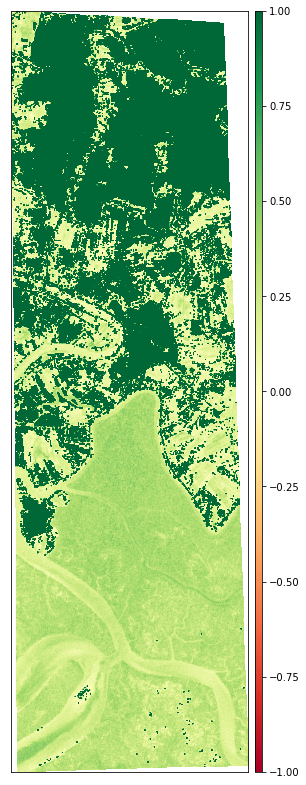

In [ ]:
ep.plot_bands(vari, cmap="RdYlGn", cols=1, vmin=-1, vmax=1, figsize=(10, 14))

plt.show()

## Distribution of NDVI, SAVI, and VARI pixel values

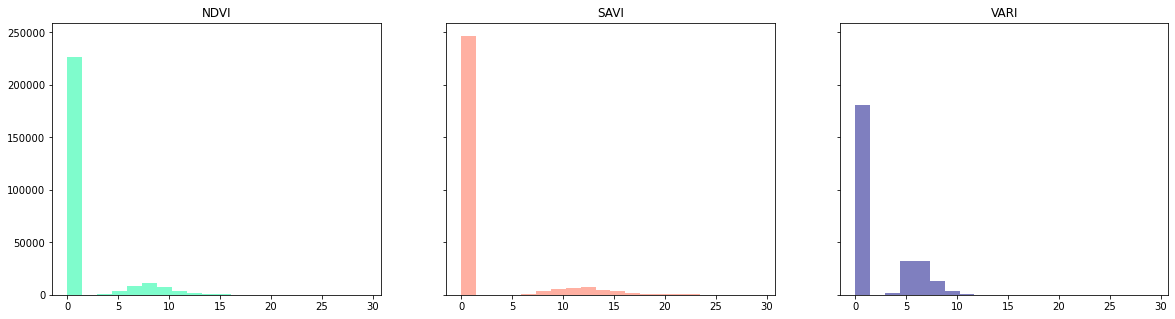

In [ ]:
ep.hist(np.stack([ndvi, savi, vari]),
        alpha=0.5,
        cols=3,
        figsize=(20, 5),
        title = ['NDVI', 'SAVI', 'VARI'],
        colors = ['mediumspringgreen', 'tomato', 'navy'])
plt.show()

# Water Indices

## Índice de Agua de Diferencia Normalizada Modificado (MNDWI)

```
MNDWI = (Green - SWIR) / (Green + SWIR)
```
* Green = valores de los píxeles en la banda verde
* SWIR = valores de los píxeles en la banda del infrarrojo de onda corta

In [1]:
mndwi = es.normalized_diff(arr_st[2], arr_st[10])

NameError: ignored

In [ ]:
ep.plot_bands(mndwi, cmap="RdYlGn", cols=1, vmin=-1, vmax=1, figsize=(10, 14))

plt.show()

## Índice de Humedad de Diferencia Normalizada (NDMI)

```
NDMI = (NIR - SWIR1)/(NIR + SWIR1)
```
* NIR = valores de los píxeles en la banda del infrarrojo cercano
* SWIR1 = valores de los píxeles en la banda 1 del infrarrojo de onda corta

In [ ]:
ndmi = es.normalized_diff(arr_st[7], arr_st[10])

In [ ]:
ep.plot_bands(ndmi, cmap="RdYlGn", cols=1, vmin=-1, vmax=1, figsize=(10, 14))

plt.show()

# Geology Indices

## Minerales de arcilla
```
Clay Minerals Ratio = SWIR1 / SWIR2
```
* SWIR1 = valores de los píxeles en la banda 1 del infrarrojo de onda corta
* SWIR2 = valores de los píxeles en la banda 2 del infrarrojo de onda corta

In [ ]:
cmr = np.divide(arr_st[10], arr_st[11])

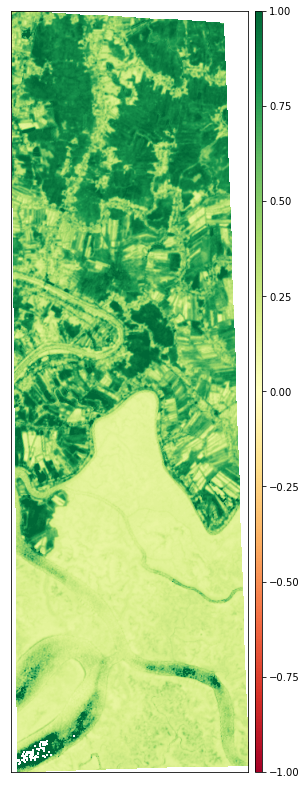

In [ ]:
ep.plot_bands(cmr, cmap="RdYlGn", cols=1, vmin=-1, vmax=1, figsize=(10, 14))

plt.show()

## Minerales ferrosos

```
Ferrous Minerals Ratio = SWIR / NIR
```

* SWIR = valores de los píxeles en la banda del infrarrojo de onda corta
* NIR = valores de los píxeles en la banda del infrarrojo cercano

In [ ]:
fmr = np.divide(arr_st[10], arr_st[7])

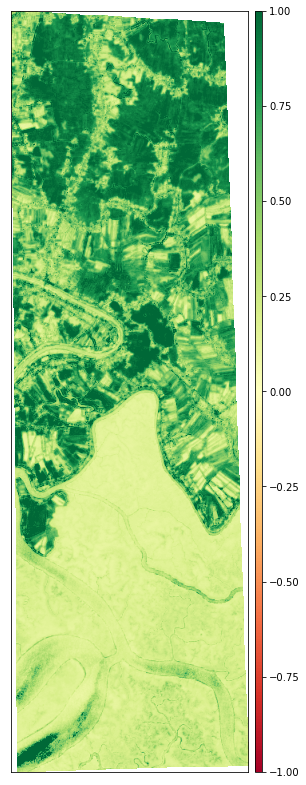

In [ ]:
ep.plot_bands(fmr, cmap="RdYlGn", cols=1, vmin=-1, vmax=1, figsize=(10, 14))

plt.show()

In [ ]:
#importar uan imagen compuesta
composite = gdal.Open(r'G:\My Drive\CATEDRA\SENSORES REMOTOS\Imagen\barranquilla\Composite_LE70090532003066EDC00.tif')

#para saber el número de bandas
print(composite.RasterCount)

In [ ]:
# Reservar el arreglo usando el tipo de dato de la primera banda
image_datatype = composite.GetRasterBand(1).DataType

# Reservar el arreglo, pero de forma más eficiente
image = np.zeros((composite.RasterYSize, composite.RasterXSize, composite.RasterCount))

In [ ]:
# Ajustar el indice y pasar a capa image
for b in range(composite.RasterCount):
    # Recuerde: GDAL indexa desde 1 y Python desde 0, así que se suma 1 en las llamadas a GDAL
    bandas = composite.GetRasterBand(b + 1)

    # Leer los datos de la banda en la tercera dimensión del arreglo
    image[:, :, b] = bandas.ReadAsArray()

In [ ]:
print(image)
print(image.shape)

In [ ]:
#calcular el NDVI utilizando bandas
b2 = np.ndarray.flatten(image[:, :, 2])
b3 = np.ndarray.flatten(image[:, :, 3])

#plotear scatter
plt.scatter(b2, b3)

In [ ]:
#con formato
plt.scatter(b2, b3, color='r', marker='o')
plt.xlabel('Red Reflectance')
plt.ylabel('NIR label')
plt.title('Red vs NIR')

In [ ]:
# usar "imshow" para una imagen: nir en la primera subgráfica, rojo en la segunda
plt.subplot(121)
plt.imshow(image[:, :, 3], cmap=plt.cm.Greys)
plt.colorbar()

In [ ]:
# Ahora la banda roja en la segunda subgráfica (indicada por el último de los 3 números)
plt.subplot(122)
plt.imshow(image[:, :, 2], cmap=plt.cm.Greys)
plt.colorbar()

In [ ]:
#calcular el NDVI utilizando la imagen compuesta
ndvi1 = ((image[:, :, 3] - image[:, :, 2]) / (image[:, :, 3] + image[:, :, 2])).astype(np.float64)
plt.imshow(ndvi1)
plt.colorbar()

In [ ]:
#calcular el NDVI utilizando la imagen compuesta
b3= image[:, :, 3]
b2= image[:, :, 2]
suma= b3+b2
resta=b3-b2
ndvi2= (resta/suma).astype(np.float64)
plt.imshow(ndvi2)
plt.colorbar()

In [ ]:
# create new file
driver = gdal.GetDriverByName('GTiff')
file = driver.Create( 'G:/My Drive/ndvi.tif', composite.RasterXSize , composite.RasterYSize , 1)
file.GetRasterBand(1).WriteArray(ndvi3)

In [ ]:
# spatial ref system
proj = composite.GetProjection()
georef = composite.GetGeoTransform()
file.SetProjection(proj)
file.SetGeoTransform(georef)
file.GetRasterBand(1).SetNoDataValue(-9999)
file.FlushCache()

## Unsupervised Learning
### Preprocessing

In [ ]:
x = np.moveaxis(arr_st, 0, -1)
x.shape

In [ ]:
x.reshape(-1, 12).shape, 954*298

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X_data = x.reshape(-1, 12)

scaler = StandardScaler().fit(X_data)

X_scaled = scaler.transform(X_data)

X_scaled.shape

# Principal Component Analysis (PCA)

In [ ]:
pca = PCA(n_components = 4)

pca.fit(X_scaled)

data = pca.transform(X_scaled)

In [ ]:
data.shape

In [ ]:
pca.explained_variance_ratio_

In [ ]:
np.sum(pca.explained_variance_ratio_)

In [ ]:
ep.plot_bands(np.moveaxis(data.reshape((954, 298, data.shape[1])), -1, 0),
              cmap = 'gist_earth',
              cols = 4,
              title = [f'PC-{i}' for i in range(1,5)])

plt.show()

## *k* - Means

In [ ]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters = 6)

kmeans.fit(data)

In [ ]:
labels = kmeans.predict(data)

In [ ]:
np.unique(labels)

In [ ]:
ep.plot_bands(labels.reshape(954, 298), cmap=ListedColormap(['darkgreen', 'green', 'black', '#CA6F1E', 'navy', 'forestgreen']))
plt.show()

In [ ]:
import plotly.express as px

fig = px.imshow(labels.reshape(954, 298),
          color_continuous_scale = ['darkgreen', 'green', 'black', '#CA6F1E', 'navy', 'forestgreen'])

fig.update_xaxes(showticklabels=False)

fig.update_yaxes(showticklabels=False)

fig.update_layout(
    autosize=False,
    width=500,
    height=1000,
    margin=dict(
        l=50,
        r=50,
        b=100,
        t=100,
        pad=4
    ),
    # paper_bgcolor="LightSteelBlue",
)

### Kenya example

In [ ]:
dataarray = rxr.open_rasterio('https://drive.google.com/u/0/uc?id=1Kb3gP9v-xsNJ_AzGJE1jbatvdKtvf0zx&export=download')
dataarray

<xarray.DataArray (band: 1, y: 213, x: 179)>
array([[[nan, nan, ..., nan, nan],
        [nan, nan, ..., nan, nan],
        ...,
        [nan, nan, ..., nan, nan],
        [nan, nan, ..., nan, nan]]], dtype=float32)
Coordinates:
  * band         (band) int64 1
  * y            (y) float64 4.641 4.596 4.551 4.507 ... -4.791 -4.836 -4.881
  * x            (x) float64 33.91 33.96 34.0 34.05 ... 41.77 41.82 41.86 41.91
    spatial_ref  int64 0
Attributes:
    scale_factor:  1.0
    add_offset:    0.0
    long_name:     elevation
    grid_mapping:  spatial_ref

Sin entrar en los detalles de este formato, vemos que los datos tienen una dimensión de 218 por 179 con una sola banda: la elevación. También vemos que los valores de x están aproximadamente entre 30 y 42, y los de y entre -5 y 5, así que parecen valores razonables de coordenadas.

Para familiarizarnos un poco más con los datos, podemos convertirlos fácilmente a un conjunto de datos de pandas y mostrarlo. Se ve que efectivamente es un conjunto de datos en grilla, con las coordenadas como encabezados de filas y columnas y la elevación en metros como valores. (Los valores NaN, o Not a Number, son datos faltantes, porque los datos se recortaron a la forma de las fronteras de Kenia.)

In [ ]:
# dataarray[0] es la primera banda del dataarray
df = dataarray[0].to_pandas()
# display the first 10 columns and 10 rows
df.iloc[0:20, 0:20]

x,33.911327,33.956243,34.001159,34.046074,34.090990,34.135906,34.180822,34.225737,34.270653,34.315569,34.360485,34.405400,34.450316,34.495232,34.540148,34.585063,34.629979,34.674895,34.719811,34.764727
y,,,,,,,,,,,,,,,,,,,,
4.641321,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4.596405,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,539.0,519.0,512.0,499.0,488.0,484.0,477.0,474.0,471.0,470.0
4.551489,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,561.0,634.0,566.0,523.0,501.0,490.0,487.0,482.0,478.0,477.0,475.0
4.506573,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,577.0,587.0,847.0,1040.0,674.0,508.0,499.0,497.0,490.0,486.0,483.0,478.0
4.461658,NaN,NaN,NaN,NaN,NaN,NaN,NaN,610.0,584.0,605.0,850.0,1010.0,639.0,517.0,505.0,502.0,497.0,489.0,486.0,480.0
4.416742,NaN,NaN,NaN,NaN,NaN,NaN,660.0,641.0,603.0,617.0,1145.0,770.0,569.0,532.0,518.0,513.0,506.0,496.0,492.0,485.0
4.371826,NaN,NaN,NaN,NaN,NaN,697.0,681.0,646.0,634.0,657.0,986.0,624.0,578.0,541.0,531.0,526.0,516.0,505.0,500.0,492.0
4.326910,NaN,NaN,NaN,NaN,740.0,706.0,690.0,647.0,653.0,690.0,1117.0,726.0,570.0,547.0,537.0,533.0,522.0,509.0,503.0,495.0
4.281995,NaN,NaN,NaN,797.0,758.0,714.0,695.0,667.0,664.0,711.0,1138.0,688.0,583.0,563.0,552.0,547.0,530.0,516.0,510.0,502.0


Incluso podemos exportar y descargar los datos como un archivo CSV y abrirlo en Excel si lo deseamos.

In [ ]:
# El archivo convertido se encuentra haciendo clic en el ícono 'Files' a la izquierda
df.to_csv('kenya/elevation_export_5000.csv')